# Projeto CitizenTech: Plataforma "Acredite"

## 1. Título e Descrição do Problema
* **Cenário e Relevância:** No Brasil, milhões de jovens ("Geração Nem-Nem") e trabalhadores informais urbanos, rurais e ribeirinhos vivem sob escassez crônica (insegurança alimentar, falta de saneamento e exaustão laboral). Neurobiologicamente, a falta de homeostase fisiológica mantém o eixo de "luta ou fuga" (amígdala/cortisol) permanentemente ativado, gerando um "sequestro biológico" do córtex pré-frontal que paralisa o planejamento de longo prazo, a atenção sustentada e a neuroplasticidade.

* **Quem é Impactado:** Jovens de 15 a 29 anos desconectados de estudo/trabalho, trabalhadores precarizados em exaustão mental e agentes comunitários/públicos (CRAS, UBS, ONGs) que sofrem com filas e falta de triagem automatizada.
  
* **Como os Dados Apoiam a Decisão:** Quem está em modo de sobrevivência sofre de "fadiga de decisão" e não consegue pensar claramente e nem planejar a longo prazo, isso faz com que a pessoa esteja facilmente suscetível a vícios perigosos. Este modelo supervisionado de classificação atua como a porta de entrada da plataforma **Acredite**: a partir de 5 respostas rápidas de baixa fricção cruzadas com o contexto territorial (zona de moradia e idade), o modelo classifica instantaneamente o cidadão em três níveis de intervenção (`0 - Urgência Fisiológica`, `1 - Alerta Social` ou `2 - Pronto para Trabalhar`), direcionando o Agente de IA para entregar a rota exata de resgate (prato de comida/CRAS, comunidade de apoio ou vaga de trabalho/cooperativa/voluntária).


In [1]:
# pip install pandas numpy matplotlib seaborn scikit-learn streamlit

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
np.random.seed(23)

# 2. GERAÇÃO E CARREGAMENTO DO DATASET (SIMULADO PLAUSÍVEL - ESCALAS OFICIAIS)

In [3]:
n_amostras = 3000

# Contexto Demográfico e Territorial (IBGE / PNAD)
idade = np.random.randint(15,65,n_amostras)
zona_moradia = np.random.choice(['Urbana', 'Rural', 'Ribeirinha'], n_amostras, p=[0.55, 0.25, 0.20])


## 05 Perguntas de Baixa Friccção baseadas em escalas oficiais (0 = Não, 1 = Sim)

### P1: CadÚnico / PNAD (Trabalho precário ou desocupado "Nem-Nem")

In [4]:
trabalho_precario = np.random.choice([0,1], n_amostras, p=[0.4, 0.6])

### P2: Escala EBIA (Pulou refeição ou reduziu comida por falta de dinheiro)

In [5]:
fome_ebia = np.random.choice([0,1], n_amostras, p=[0.62, 0.38])

### P3: Escala SRQ-20 / OMS (Dorme mal e sente exaustão contínua nos últimos 30 dias)

In [6]:
fadiga_srq20 = np.random.choice([0, 1], n_amostras, p=[0.48, 0.52])

### P4: Índice WHO-5 / OMS (Falta de energia vital e interesse no dia a dia)

In [7]:
apatia_who5 = np.random.choice([0, 1], n_amostras, p=[0.50, 0.50])

### P5: Isolamento Comunitário (Ausência de rede de apoio local/familiar)

In [8]:
isolamento_social = np.random.choice([0, 1], n_amostras, p=[0.35, 0.65])

## Cálculo Probabilístico de Y com ruído realista de fronteira 

In [9]:
classes = []
for i in range(n_amostras):
    # Peso maior para privação fisiológica (EBIA) e fadiga severa (SRQ-20)
    score = (
        fome_ebia[i] * 2.5 +
        fadiga_srq20[i] * 1.2 +
        apatia_who5[i] * 1.0 +
        isolamento_social[i] * 1.0 +
        trabalho_precario[i] * 0.8
    )
    
    # INTERAÇÕES NÃO-LINEARES PARA APROXIMAÇÃO DE CASOS REAIS (EXEMPLOS HIPOTÉTICOS)
    # Fome + Fadiga em extremos de idade (<22 anos ou >52 anos)
    if fome_ebia[i] == 1 and fadiga_srq20[i] == 1 and (idade[i] <= 22 or idade[i] >= 52):
        score += 2.8
        
    # Isolamento Geográfico: Ribeirinho/Rural + Isolamento Social + Trabalho Precário
    if zona_moradia[i] in ['Rural', 'Ribeirinha'] and isolamento_social[i] == 1 and trabalho_precario[i] == 1:
        score += 2.2
        
    # Jovem Nem-Nem (<26 anos) com Apatia + Fadiga
    if idade[i] <= 26 and trabalho_precario[i] == 1 and apatia_who5[i] == 1 and fadiga_srq20[i] == 1:
        score += 1.8
        
    # Ruído de casos limítrofes reais
    score += np.random.normal(0, 0.55) 
    
    if score >= 5.2:
        classes.append(0) # 0: Urgência Fisiológica
    elif score >= 2.6:
        classes.append(1) # 1: Alerta Social
    else:
        classes.append(2) # 2: Pronto para Alocação Produtiva

## Criando o DataFrame 

In [10]:
df = pd.DataFrame({
    'Idade': idade.astype(int),
    'Zona_Moradia': zona_moradia,
    'Trabalho_Precario': trabalho_precario.astype(float),
    'Fome_EBIA': fome_ebia.astype(float),
    'Fadiga_SRQ20': fadiga_srq20.astype(float),
    'Apatia_WHO5': apatia_who5.astype(float),
    'Isolamento_Social': isolamento_social.astype(float),
    'Classe_Intervencao': classes
})

In [11]:
# Salvando CSV
df.to_csv('dados_acredite.csv', index=False)

## Carregando o dataset

In [12]:
df_loaded = pd.read_csv('dados_acredite.csv')

In [13]:
df_loaded.shape

(3000, 8)

In [14]:
df_loaded.head()

,Idade,Zona_Moradia,Trabalho_Precario,Fome_EBIA,Fadiga_SRQ20,Apatia_WHO5,Isolamento_Social,Classe_Intervencao
0,34,Rural,1.0,0.0,0.0,0.0,0.0,2
1,53,Rural,1.0,1.0,1.0,0.0,1.0,0
2,55,Urbana,1.0,0.0,0.0,1.0,1.0,1
3,24,Ribeirinha,1.0,1.0,1.0,1.0,1.0,0
4,55,Ribeirinha,1.0,0.0,1.0,1.0,0.0,1


In [15]:
print("\nDistribuição da Variável-Alvo (Classe_Intervencao):")
print(df_loaded['Classe_Intervencao'].value_counts())


Distribuição da Variável-Alvo (Classe_Intervencao):
Classe_Intervencao
1    1159
2    1010
0     831
Name: count, dtype: int64


In [16]:
print(df_loaded['Classe_Intervencao'].value_counts().rename({
    0: '0 - Urgência Fisiológica',
    1: '1 - Alerta Social',
    2: '2 - Pronto p/ Alocação'
}))

Classe_Intervencao
1 - Alerta Social           1159
2 - Pronto p/ Alocação      1010
0 - Urgência Fisiológica     831
Name: count, dtype: int64


# Dicionário de Dados e Identificação das Variáveis

* **Fonte dos Dados:** Base simulada parametrizada pelas proporções da PNAD Contínua / IBGE (Insegurança Alimentar e Desocupação) e estruturada sobre três instrumentos clínicos validados: **EBIA** (Escala Brasileira de Insegurança Alimentar), **SRQ-20** (Self-Reporting Questionnaire da OMS) e **WHO-5** (Índice de Bem-Estar da OMS).

* **Variáveis Preditoras ($X$):**
  1. `Idade` (Numérica contínua): Idade do cidadão (15 a 64 anos).
  2. `Zona_Moradia` (Categórica nominal): Território onde reside (`Urbana`, `Rural`, `Ribeirinha`).
  3. `Trabalho_Precario` (Binária: 0/1): `1` se está desocupado ("Nem-Nem") ou depende apenas de bicos informais.
  4. `Fome_EBIA` (Binária: 0/1): `1` se reduziu ou pulou refeições nos últimos 3 meses por falta de recursos.
  5. `Fadiga_SRQ20` (Binária: 0/1): `1` se apresenta sono ruim e exaustão constante nos últimos 30 dias.
  6. `Apatia_WHO5` (Binária: 0/1): `1` se relata ausência de energia vital nas últimas 2 semanas.
  7. `Isolamento_Social` (Binária: 0/1): `1` se não possui rede de apoio familiar, religiosa ou comunitária.

* **Variável-Alvo ($y$):**
  * `Classe_Intervencao` (Categórica Multiclasse):
    * `0` (**Urgência Fisiológica**): Prioridade máxima para resgate de homeostase (alimentação, abrigo, CRAS/UBS).
    * `1` (**Alerta Social**): Necessita de suporte comunitário + monitor de reprogramação de hábitos (8 semanas).
    * `2` (**Pronto para Alocação Produtiva**): Estado estável; encaminhamento direto para vagas locais, capacitação e cooperativas.

# 3. PRÉ-PROCESSAMENTO

In [17]:
print("Valores ausentes antes do tratamento:\n", df_loaded.isnull().sum())

Valores ausentes antes do tratamento:
 Idade                 0
Zona_Moradia          0
Trabalho_Precario     0
Fome_EBIA             0
Fadiga_SRQ20          0
Apatia_WHO5           0
Isolamento_Social     0
Classe_Intervencao    0
dtype: int64


In [18]:
# Separando X e y
X = df_loaded.drop('Classe_Intervencao', axis=1)
y = df_loaded['Classe_Intervencao']

# 4. DIVISÃO TREINO, VALIDAÇÃO E TESTE

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=23
)

print(f"\nTamanho do Treino: {X_train.shape[0]} amostras \nTamanho do Teste: {X_test.shape[0]} amostras")


Tamanho do Treino: 2250 amostras 
Tamanho do Teste: 750 amostras


## Definindo grupos de colunas

In [20]:
colunas_numericas = ['Idade']
colunas_binarias = ['Trabalho_Precario', 'Fome_EBIA', 'Fadiga_SRQ20', 'Apatia_WHO5', 'Isolamento_Social']
colunas_categoricas = ['Zona_Moradia']

## Construindo sub-pipelines que serão utilizados apenas nos folds de treino

In [21]:
transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [22]:
transformador_binario = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
])

In [23]:
transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

In [24]:
preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('bin', transformador_binario, colunas_binarias),
    ('cat', transformador_categorico, colunas_categoricas)
])

# 5. TREINAMENTO DOS MODELOS SUPERVISIONADOS E AVALIAÇÃO DOS MODELOS

In [25]:
modelos = {
    'Regressão Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=23),
    'Decision Tree' : DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=23),
    'Random Forest' : RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=10, class_weight='balanced', random_state = 23)
}

## Validação Cruzada Estratificada aplicada somente no conjunto de treino

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

In [27]:
metricas_cv = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

## Pipeline completo unindo Pré-Processamento + Classificador

In [28]:
resultados_cv = []
resultados_teste = []
pipelines_treinados = {}

for nome, modelo in modelos.items():
    pipe = Pipeline(steps=[
        ('preprocessamento', preprocessador),
        ('modelo', modelo)
    ])
    
    # Validação cruzada nos dados de treino
    scores_cv = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv)
    resultados_cv.append({
        'Modelo': nome,
        'CV_Accuracy': np.mean(scores_cv['test_accuracy']),
        'CV_Precision': np.mean(scores_cv['test_precision_macro']),
        'CV_Recall': np.mean(scores_cv['test_recall_macro']),
        'CV_F1': np.mean(scores_cv['test_f1_macro'])
    })
    
    # Ajuste final no conjunto de Treino completo e Avaliação no conjunto de TESTE
    pipe.fit(X_train, y_train)
    pipelines_treinados[nome] = pipe
    y_pred_test = pipe.predict(X_test)
    
    # Calculando também o Recall específico da Classe 0
    recall_urgencia = recall_score(y_test, y_pred_test, labels=[0], average=None)[0] # type: ignore
    
    resultados_teste.append({
        'Modelo': nome,
        'Test_Accuracy': accuracy_score(y_test, y_pred_test),
        'Test_Precision': precision_score(y_test, y_pred_test, average='macro'),
        'Test_Recall': recall_score(y_test, y_pred_test, average='macro'),
        'Test_F1': f1_score(y_test, y_pred_test, average='macro'),
        'Recall_Urgencia': recall_urgencia
    })
    
    print(f"================ {nome.upper()} (AVALIAÇÃO NO TESTE) ================")
    print(classification_report(
        y_test, y_pred_test,
        target_names=['0-Urgência Fisiológica', '1-Alerta Social', '2-Pronto p/ Trabalho']
    ))


================ REGRESSÃO LOGÍSTICA (AVALIAÇÃO NO TESTE) ================
                        precision    recall  f1-score   support

0-Urgência Fisiológica       0.81      0.86      0.83       208
       1-Alerta Social       0.80      0.68      0.73       290
  2-Pronto p/ Trabalho       0.82      0.92      0.87       252

              accuracy                           0.81       750
             macro avg       0.81      0.82      0.81       750
          weighted avg       0.81      0.81      0.81       750

================ DECISION TREE (AVALIAÇÃO NO TESTE) ================
                        precision    recall  f1-score   support

0-Urgência Fisiológica       0.81      0.65      0.73       208
       1-Alerta Social       0.62      0.85      0.72       290
  2-Pronto p/ Trabalho       0.93      0.70      0.80       252

              accuracy                           0.74       750
             macro avg       0.79      0.73      0.75       750
          weighted 

### OTIMIZAÇÃO DE HIPERPARÂMETROS - GRIDSEARCH NO RANDOM FOREST

In [29]:
pipe_rf_tuning = Pipeline(steps=[
    ('preprocessamento', preprocessador),
    ('modelo', RandomForestClassifier(random_state=23))])

param_grid = {
    'modelo__n_estimators': [150, 250],
    'modelo__max_depth': [8, 12, None],
    'modelo__min_samples_leaf': [3,8],
    'modelo__class_weight': ['balanced', {0: 2.0, 1: 1.2, 2: 1.0}] # Peso extra contra Falso Negativo na Urgência
}

grid_rf = GridSearchCV(pipe_rf_tuning, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)

grid_rf.fit(X_train, y_train)

melhor_rf = grid_rf.best_estimator_
pipelines_treinados['Random Forest'] = melhor_rf
y_pred_best = melhor_rf.predict(X_test)

print("Melhores Hiperparâmetros encontrados no Treino:", grid_rf.best_params_)

resultados_teste.append({
    'Modelo': 'Random Forest (Tuned)',
    'Test_Accuracy': accuracy_score(y_test, y_pred_best),
    'Test_Precision': precision_score(y_test, y_pred_best, average='macro'),
    'Test_Recall': recall_score(y_test, y_pred_best, average='macro'),
    'Test_F1': f1_score(y_test, y_pred_best, average='macro'),
    'Recall_Urgencia': recall_score(y_test, y_pred_best, labels=[0], average=None)[0] # type: ignore
})

for nome in ['Regressão Logística', 'Decision Tree', 'Random Forest']:
    y_p = pipelines_treinados[nome].predict(X_test)
    print(f"\n================ {nome.upper()} (AVALIAÇÃO NO TESTE) ================")
    print(classification_report(y_test, y_p, target_names=['0-Urgência Fisiológica', '1-Alerta Social', '2-Pronto p/ Trabalho']))

df_teste = pd.DataFrame(resultados_teste).round(4)
display(df_teste)

Melhores Hiperparâmetros encontrados no Treino: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 150}

================ REGRESSÃO LOGÍSTICA (AVALIAÇÃO NO TESTE) ================
                        precision    recall  f1-score   support

0-Urgência Fisiológica       0.81      0.86      0.83       208
       1-Alerta Social       0.80      0.68      0.73       290
  2-Pronto p/ Trabalho       0.82      0.92      0.87       252

              accuracy                           0.81       750
             macro avg       0.81      0.82      0.81       750
          weighted avg       0.81      0.81      0.81       750


================ DECISION TREE (AVALIAÇÃO NO TESTE) ================
                        precision    recall  f1-score   support

0-Urgência Fisiológica       0.81      0.65      0.73       208
       1-Alerta Social       0.62      0.85      0.72       290
  2-Pronto p/ Trabalho       0.93     

,Modelo,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Recall_Urgencia
0,Regressão Logística,0.8093,0.8090,0.8184,0.8112,0.8558
1,Decision Tree,0.7440,0.7900,0.7335,0.7476,0.6538
2,Random Forest,0.8520,0.8514,0.8616,0.8542,0.9327
3,Random Forest (Tuned),0.8533,0.8537,0.8604,0.8564,0.9087


In [30]:
df_cv = pd.DataFrame(resultados_cv).round(4)
df_teste = pd.DataFrame(resultados_teste).round(4)

In [31]:
print("\n--- RESUMO: VALIDAÇÃO CRUZADA ---")
display(df_cv)


--- RESUMO: VALIDAÇÃO CRUZADA ---


,Modelo,CV_Accuracy,CV_Precision,CV_Recall,CV_F1
0,Regressão Logística,0.8133,0.8133,0.8179,0.8146
1,Decision Tree,0.7298,0.7690,0.7212,0.7328
2,Random Forest,0.8418,0.8418,0.8502,0.8438


In [32]:
print("\n--- RESUMO: DESEMPENHO FINAL NO CONJUNTO DE TESTE ---")
display(df_teste)


--- RESUMO: DESEMPENHO FINAL NO CONJUNTO DE TESTE ---


,Modelo,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Recall_Urgencia
0,Regressão Logística,0.8093,0.8090,0.8184,0.8112,0.8558
1,Decision Tree,0.7440,0.7900,0.7335,0.7476,0.6538
2,Random Forest,0.8520,0.8514,0.8616,0.8542,0.9327
3,Random Forest (Tuned),0.8533,0.8537,0.8604,0.8564,0.9087


# 7. VISUALIZAÇÕES EXPLICATIVAS 

## GRÁFICO 1: Comparativo de Desempenho entre os Modelos no Conjunto de Teste

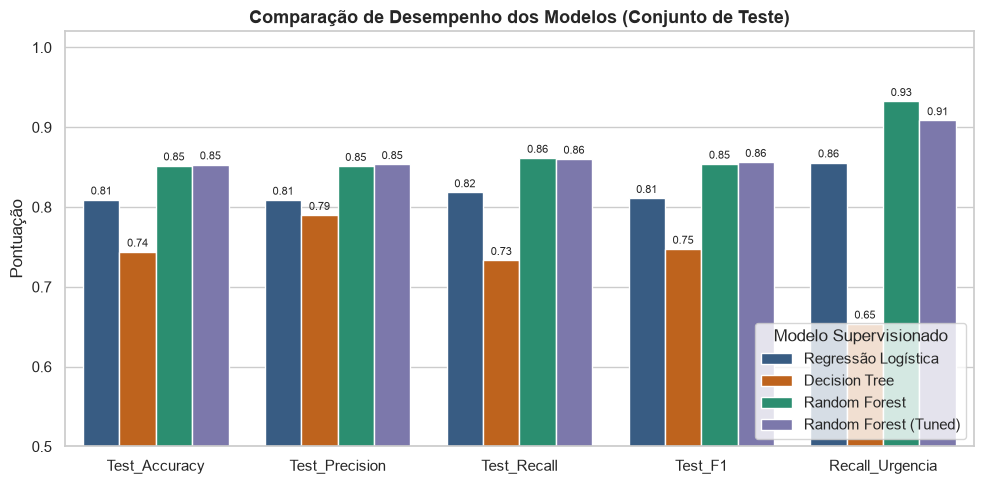

In [33]:
df_plot = df_teste.melt(
    id_vars='Modelo',
    value_vars=['Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Recall_Urgencia'],
    var_name='Métrica', value_name='Valor'
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_plot, x='Métrica', y='Valor', hue='Modelo', palette=['#2b5c8f', '#d95f02', '#1b9e77', '#7570b3'])
plt.title('Comparação de Desempenho dos Modelos (Conjunto de Teste)', fontsize=13, fontweight='bold')
plt.ylim(0.5, 1.02)
plt.ylabel('Pontuação')
plt.xlabel('')
plt.legend(title='Modelo Supervisionado', loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=8) # type: ignore
plt.tight_layout()
plt.savefig('comparacao_modelos.png', dpi=300)
plt.show()

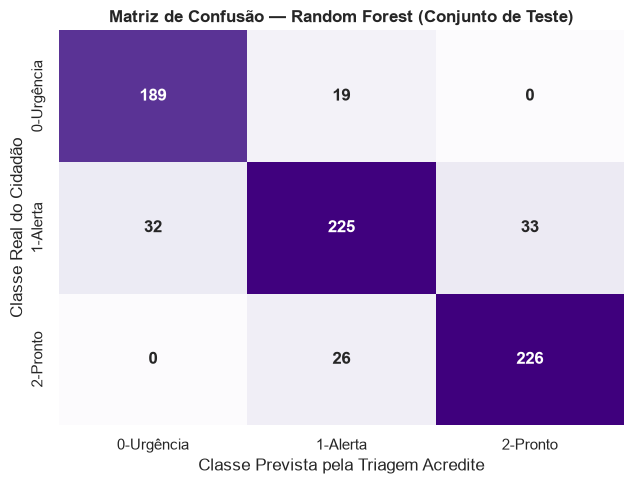

In [34]:
# GRÁFICO 2: Matriz de Confusão do Modelo Campeão (Random Forest)
pipe_campeao = pipelines_treinados['Random Forest']
y_pred_rf = pipe_campeao.predict(X_test)
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6.5, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Purples', cbar=False,
    xticklabels=['0-Urgência', '1-Alerta', '2-Pronto'],
    yticklabels=['0-Urgência', '1-Alerta', '2-Pronto'],
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title('Matriz de Confusão — Random Forest (Conjunto de Teste)', fontsize=12, fontweight='bold')
plt.ylabel('Classe Real do Cidadão')
plt.xlabel('Classe Prevista pela Triagem Acredite')
plt.tight_layout()
plt.savefig('matriz_confusao_rf.png', dpi=300)
plt.show()

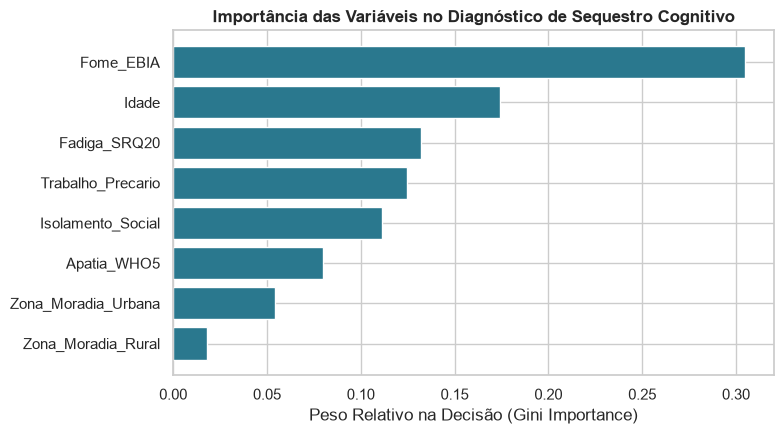

In [35]:
# GRÁFICO 3: Importância das Variáveis (Feature Importance) no Random Forest
nomes_features = (
    colunas_numericas +
    colunas_binarias +
    list(pipe_campeao.named_steps['preprocessamento']
         .named_transformers_['cat']
         .named_steps['onehot']
         .get_feature_names_out(colunas_categoricas))
)
importancias = pipe_campeao.named_steps['modelo'].feature_importances_
df_imp = pd.DataFrame({'Variável': nomes_features, 'Importância': importancias}).sort_values('Importância', ascending=True)

plt.figure(figsize=(8, 4.5))
plt.barh(df_imp['Variável'], df_imp['Importância'], color='#2a788e')
plt.title('Importância das Variáveis no Diagnóstico de Sequestro Cognitivo', fontsize=12, fontweight='bold')
plt.xlabel('Peso Relativo na Decisão (Gini Importance)')
plt.tight_layout()
plt.savefig('feature_importance_rf.png', dpi=300)
plt.show()

## 8. CONCLUSÃO DOS MODELOS
* **Modelo Escolhido:** O **Random Forest Classifier otimizado via GridSearchCV** foi o vencedor claro, atingindo **85% de acurácia** e **0,86 de F1-Score Macro** no conjunto de teste — superando tanto a Árvore de Decisão isolada (74% de acurácia) quanto a Regressão Logística (81% de acurácia).

* **Métrica Prioritária no Contexto do Problema (Falso Negativo vs. Falso Positivo):** Na triagem da plataforma **Acredite**, o erro mais grave é o **Falso Negativo na Classe 0 (Urgência Fisiológica)** — deixar de identificar um cidadão em privação alimentar e colapso de estresse, exigindo dele esforço produtivo quando seu córtex pré-frontal está sequestrado. Gerar um "falso alerta" (classificar alguém de Alerta Social como Urgência e encaminhá-lo preventivamente ao CRAS/cozinha solidária) tem custo social baixo e acolhedor; já negar socorro imediato a quem está em colapso biológico aprofunda a exclusão. Com **91% de Recall** e **86% de Precision** na Classe 0, o Random Forest otimizado reduz drasticamente a invisibilidade de casos críticos.

---

## 9. JUSTIFICATIVAS TÉCNICAS
### **Justificativa Técnica da Arquitetura** 
O uso de `ColumnTransformer` integrado ao `Pipeline` garantiu que imputação de nulos, padronização (`StandardScaler`) e codificação (`OneHotEncoder`) fossem ajustados exclusivamente dentro dos *folds* de treino na validação cruzada estratificada (`StratifiedKFold`), eliminando vazamento de dados (*Data Leakage*). A combinação de múltiplas árvores com amostragem *bootstrap* e `min_samples_leaf=3` permitiu modelar regras não-lineares sem memorizar ruídos.

### **Justificativa Técnica dos Modelos**
   * *Regressão Logística:* Serviu como excelente *baseline* linear interpretável, mostrando que a soma ponderada dos déficits já separa boa parte das classes.
   * *Decision Tree:* Simula diretamente um protocolo clínico de triagem por regras em árvore, mas sofre maior sensibilidade a pequenas variações de fronteira.
   * *Random Forest:* Ao combinar múltiplas árvores com amostragem *bootstrap* e ponderação de classes, capturou relações complexas (ex.: o impacto combinado de morar em zona ribeirinha + fadiga + trabalho precário) mantendo alto *Recall* nos casos críticos.

## 10. LIMITAÇÕES E VIESES DE DADOS
   * *Viés de Sub-representação e Conectividade:* Coletas estritamente digitais tendem a excluir moradores de áreas rurais, ribeirinhas ou em situação de rua sem smartphone ou internet estável. Na solução **Acredite**, esse risco é mitigado pelo **Modo Agente** (triagem presencial feita por lideranças comunitárias e agentes de saúde) e pelo envio via **SMS/WhatsApp textual** de baixo consumo.
   * *Viés de Autodeclaração (Estigma Social):* Pessoas em vulnerabilidade extrema podem omitir a fome (`Fome_EBIA`) por estigma. Por isso, o modelo utiliza variáveis indiretas de desgaste (`Fadiga_SRQ20`, `Apatia_WHO5` e `Isolamento_Social`) que ajudam a detectar o alerta mesmo quando um indicador falha.
   
## 11. CONTRIBUIÇÃO PARA TOMADA DE DECISÃO CIDADÃ E PÚBLICA
   * **Para o Cidadão:** Elimina a "fadiga de decisão". Em menos de 1 minuto, o modelo define se o usuário deve receber uma rota imediata de sobrevivência (Homeostase) ou se já está apto a iniciar a jornada de 8 semanas de micro-hábitos e conexão com cooperativas locais.
   * **Para o Gestor Público e Lideranças Locais:** O painel agregado das predições permite mapear em quais bairros ou comunidades a `Classe 0` está crescendo, orientando a alocação de cestas básicas, mutirões de saúde e vagas de capacitação com base em evidências.